# PBMC 3k: Clustering and Cell-Type Annotation

This notebook continues from the preprocessed PBMC 3k dataset created in **01_scRNA_seq_QC_and_Preprocessing.ipynb**. First run Notebook 1, download `pbmc3k_preprocessed.h5ad`, then upload that file when prompted below.

In [1]:
%pip install -q "anndata==0.11.4" "scanpy==1.11.5" "pandas==2.2.3" "zarr<3" igraph leidenalg

In [2]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from importlib.metadata import version

print("Pandas:", version("pandas"))
print("AnnData:", version("anndata"))
print("Scanpy:", version("scanpy"))

sc.settings.verbosity = 2

Pandas: 2.2.3
AnnData: 0.11.4
Scanpy: 1.11.5


In [8]:
from google.colab import files

uploaded = files.upload()
h5ad_file = next((name for name in uploaded if name.endswith(".h5ad")), None)

if h5ad_file is None:
    raise ValueError("Please upload pbmc3k_preprocessed.h5ad from Notebook 1.")

adata = sc.read_h5ad(h5ad_file)
print(adata)

Saving pbmc3k_preprocessed.h5ad to pbmc3k_preprocessed (1).h5ad
AnnData object with n_obs × n_vars = 2698 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p'
    layers: 'counts'


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

output_path = '/content/drive/MyDrive/Colab Notebooks/PBMC3k/data/pbmc3k_preprocessed.h5ad'

adata.write_h5ad(output_path)

In [9]:
adata_hvg = adata[:, adata.var["highly_variable"]].copy()

print(adata_hvg)

AnnData object with n_obs × n_vars = 2698 × 2000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p'
    layers: 'counts'


Identify genes whose expression varies meaningfully across cells.

The .h5ad file stores the **expression matrix**, **metadata** and **preprocessing** **results**.

In [ ]:
sc.pp.scale(adata_hvg, max_value=10)

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


<div style="font-family: 'Times New Roman', Times, serif;">

### What does scaling mean?

Genes can have very different expression ranges across cells. For example, one gene might have values mostly between 0 and 2, while another has values between 0 and 8.

Scaling standardizes each gene across all cells using a **z-score**:

$$
z = \frac{x-\mu}{\sigma}
$$

- \(x\): the gene's expression value in a particular cell
- \(\mu\): the mean expression of that gene across all cells
- \(\sigma\): the standard deviation of that gene across all cells

After scaling, each gene typically has a mean of 0 and a standard deviation of 1 across cells.

In `sc.pp.scale(adata_hvg, max_value=10)`, the argument `max_value=10` clips scaled values above 10 or below −10. This helps limit the influence of extreme values.

to clip here means `Values outside the allowed range are capped at the boundaries.`

</div>

In [8]:
from scipy.sparse import issparse

print("Original adata.X")
print("Type:", type(adata.X))
print("Is sparse:", issparse(adata.X))

print("\nScaled adata_hvg.X")
print("Type:", type(adata_hvg.X))
print("Is sparse:", issparse(adata_hvg.X))

Original adata.X
Type: <class 'scipy.sparse._csr.csr_matrix'>
Is sparse: True

Scaled adata_hvg.X


NameError: name 'adata_hvg' is not defined

### Sparse vs. Dense Matrices

A **sparse matrix** stores mostly nonzero values efficiently, making it suitable for single-cell RNA-seq data, which contains many zeros. A **dense matrix** stores every value, including zeros.

Before scaling, `adata.X` was sparse. During `sc.pp.scale(adata_hvg, max_value=10)`, Scanpy centered each gene by subtracting its mean, turning many zeros into nonzero values. Therefore, `adata_hvg.X` became a dense NumPy array (`numpy.ndarray`).

**Note:** Sparse matrices save memory, while dense matrices can simplify calculations but require more memory.

In [ ]:
print(adata_hvg)
print("Scaled matrix shape:", adata_hvg.X.shape)
print("Matrix type:", type(adata_hvg.X))

AnnData object with n_obs × n_vars = 2698 × 2000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'log1p'
    layers: 'counts'
Scaled matrix shape: (2698, 2000)
Matrix type: <class 'numpy.ndarray'>


### What is `arpack` in PCA?

`arpack` is a numerical algorithm used to calculate selected eigenvalues and eigenvectors. In PCA, these help determine the principal components that capture the main patterns of variation in the data.

In `sc.tl.pca(adata_hvg, svd_solver="arpack")`, the argument `svd_solver="arpack"` tells Scanpy to use the ARPACK solver to calculate the principal components.

**Why use it?** ARPACK can efficiently calculate a subset of principal components instead of computing the full decomposition.

**Note:** `arpack` is the solver used for the calculation, while PCA is the dimensionality-reduction method itself.

In [ ]:
sc.tl.pca(adata_hvg, svd_solver="arpack")

computing PCA
    with n_comps=50
    finished (0:00:04)


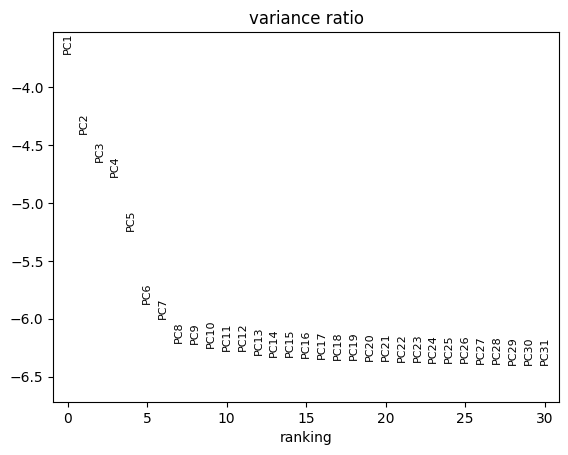

In [ ]:
sc.pl.pca_variance_ratio(adata_hvg, log=True)

### Interpreting the PCA Variance Plot

The PCA variance plot shows how much of the total variation in gene expression is explained by each principal component (PC).

- **X-axis:** Principal component number.
- **Y-axis:** Proportion of variance explained by each PC, displayed on a logarithmic scale.
- **PC1:** Captures the greatest possible amount of variation.
- **Later PCs:** Capture progressively smaller amounts of variation.

The **elbow point** is where the explained variance begins to decrease more gradually. It can help us estimate how many PCs to use for downstream analysis.

PCA calculated 50 PCs in this dataset, but we do not necessarily need to use all 50 when constructing the cell-neighbor graph.

In [ ]:
#how much variation each PC explains.
print("PCA shape:", adata_hvg.obsm["X_pca"].shape)


PCA shape: (2698, 50)


### Goal of Principal Components (PCs)

PCA reduces thousands of gene measurements into fewer variables while preserving the main patterns of variation between cells.

It combines information from multiple genes into new variables called principal components (PCs). Each PC captures a different pattern of variation.

For example, instead of analyzing 2,000 genes directly, we might use 30 PCs to represent the main patterns of variation across cells.

In [ ]:
#Build the neighbor graph
sc.pp.neighbors(
    adata_hvg,
    n_neighbors=15,
    n_pcs=50
)

print("Neighbor graph created.")
print("Graph components:", list(adata_hvg.obsp.keys()))

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:43)
Neighbor graph created.
Graph components: ['distances', 'connectivities']


### Number of PCs Used for the Neighbor Graph

PCA calculated 50 principal components (PCs), but downstream analysis can use fewer PCs.

The `n_pcs` parameter determines how many of the calculated PCs are used to compare cells when building the neighbor graph.

We use `n_pcs=50` to include all 50 calculated PCs for now. The optimal number should be evaluated using the PCA variance plot and the analysis goals.

### Build the Neighbor Graph

After calculating PCA, we build a **neighbor graph** to identify cells with similar gene expression patterns. This graph is used in downstream steps such as Leiden clustering and UMAP visualization.


### Parameters

- `adata_hvg`: The AnnData object containing the 2,000 highly variable genes, scaled expression data and PCA results.
- `n_neighbors=15`: Considers 15 nearby cells when constructing each cell's local neighborhood. This is a starting value that can be adjusted.
- `n_pcs=50`: Uses the first 50 principal components (PCs) to calculate cell similarities. We calculated 50 PCs in the previous step.

### Output

- `distances`: Stores distances between neighboring cells.
- `connectivities`: Stores the strength of connections between cells in the neighbor graph.

The exact contents of `adata_hvg.obsp` may include additional entries depending on the operations performed.

### Key Takeaway

The neighbor graph represents relationships between similar cells. It does not assign cell types or clusters by itself. Leiden uses this graph to group cells into clusters, while UMAP uses it to create a low-dimensional visualization.

### Leiden Clustering

Leiden clustering groups cells with similar gene expression patterns using the neighbor graph created in the previous step.


In [ ]:
sc.tl.leiden(
    adata_hvg,
    resolution=0.5,
    random_state=42
)

print(adata_hvg.obs["leiden"].value_counts().sort_index())

running Leiden clustering


/tmp/ipykernel_534/4250491792.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


    finished (0:00:01)
leiden
0    1219
1     665
2     426
3     354
4      34
Name: count, dtype: int64


### Parameters

- `adata_hvg`: The AnnData object containing the gene expression data, PCA results and neighbor graph.
- `resolution=0.5`: Controls cluster granularity. Lower values generally produce fewer, larger clusters, while higher values generally produce more, smaller clusters.
- `random_state=42`: Sets a random seed to help make the results reproducible.

### Output

The Leiden algorithm assigns each cell a cluster label and stores it in `adata_hvg.obs["leiden"]`.

- `adata_hvg.obs["leiden"]`: Retrieves the cluster label assigned to each cell.
- `.value_counts()`: Counts the cells in each cluster.
- `.sort_index()`: Displays clusters in numerical order.

In this analysis, the 2,698 cells were grouped into five clusters:

| Cluster | Number of cells |
|---|---:|
| 0 | 1,219 |
| 1 | 665 |
| 2 | 426 |
| 3 | 354 |
| 4 | 34 |

### Key Takeaway

Leiden clustering groups cells based on similarities in their gene expression patterns. The resulting cluster labels are computational groupings, not confirmed cell types. Marker gene analysis is needed to help identify the biological cell types represented by each cluster.

computing UMAP
    finished (0:00:06)


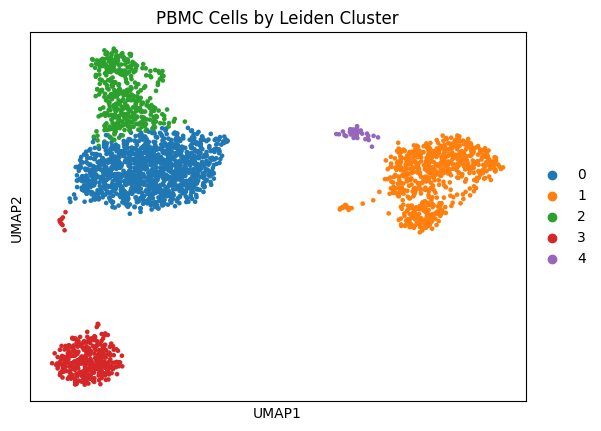

In [ ]:
sc.tl.umap(
    adata_hvg,
    random_state=42
)

sc.pl.umap(
    adata_hvg,
    color="leiden",
    title="PBMC Cells by Leiden Cluster"
)

### UMAP Visualization

UMAP (Uniform Manifold Approximation and Projection) is a dimensionality reduction technique that represents cells in a two-dimensional space. It helps visualize similarities between cells based on their gene expression patterns.

### Parameters

- `adata_hvg`: The AnnData object containing the PCA results, neighbor graph and Leiden cluster labels.
- `random_state=42`: Sets a random seed to help make the UMAP layout reproducible.
- `color="leiden"`: Colors each cell according to its assigned Leiden cluster.
- `title`: Sets the plot title.

### Output

The UMAP plot displays each cell as a dot in two dimensions. Cells with similar gene expression patterns often appear near one another.

- **Dots:** Represent individual cells.
- **Colors:** Represent the five Leiden clusters, labeled 0–4.
- **Groups of dots:** Show patterns of similarity among cells.

The UMAP coordinates are stored in `adata_hvg.obsm["X_umap"]`.

### Key Takeaway

UMAP provides a visual representation of cell similarities, while Leiden assigns cells to computational clusters. The plot can help reveal patterns and relationships, but it cannot identify cell types on its own. Marker gene analysis is needed to help determine the biological identity of each cluster.

**Important:** UMAP axes have no direct biological meaning, and distances between separated groups should be interpreted cautiously.

In [ ]:
# Transfer cluster labels to the normalized, log-transformed data
adata.obs["leiden"] = adata_hvg.obs["leiden"].reindex(
    adata.obs_names
).astype("category")

### Understanding the Two AnnData Objects

Both `adata` and `adata_hvg` contain the same 2,698 cells, but they differ in the genes they contain and how their expression values were processed.

| Property | `adata` | `adata_hvg` |
|---|---|---|
| Cells | 2,698 | 2,698 |
| Genes | All retained genes | 2,000 highly variable genes |
| Expression values | Normalized and log-transformed | Scaled for PCA |
| Leiden labels | Not yet assigned | Already assigned |

`adata_hvg` was created by selecting highly variable genes from `adata` and scaling them. PCA, neighbor graph construction and Leiden clustering were then performed using `adata_hvg`.

We now want to transfer the cluster labels to `adata` so that we can identify marker genes using the normalized, log-transformed expression values and all retained genes.

### Understanding the Code

**A. `adata.obs`**

The `obs` attribute is a pandas DataFrame containing cell-level metadata. Each row represents a cell, and columns store information such as quality-control metrics and cluster labels.

**B. `adata_hvg.obs["leiden"]`**

Retrieves the Leiden cluster label assigned to each cell. Your analysis identified five clusters: `0`, `1`, `2`, `3` and `4`.

**C. `.reindex(adata.obs_names)`**

Aligns the cluster labels with the cell names and order in `adata`.

This is important because pandas aligns data using index labels, not just row positions. Reindexing helps ensure that each cell receives its correct cluster label.

**D. `.astype("category")`**

Converts the cluster labels into a categorical variable. Cluster IDs are identifiers, not numerical measurements. For example, cluster 4 is not twice cluster 2.

**E. `adata.obs["leiden"] = ...`**

Stores the transferred labels in a new `leiden` column in `adata.obs`, making them available for downstream analysis.

### Example: Why Reindexing Matters

Suppose `adata_hvg` contains these cells and labels:

| Cell ID | Cluster |
|---|---|
| Cell_A | 0 |
| Cell_B | 1 |
| Cell_C | 0 |

If `adata` lists the cells in the order `Cell_C`, `Cell_A`, `Cell_B`, reindexing aligns the labels as `0`, `0`, `1`.

Without alignment, assigning labels based only on row positions could associate a cell with the wrong cluster.


In [ ]:
# Identify genes that distinguish each cluster
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon"
)

ranking genes
    finished (0:00:14)


### Identifying Marker Genes

The `rank_genes_groups()` function identifies genes whose expression differs between each Leiden cluster and the remaining cells. These genes help us understand the biological characteristics of each cluster.

**Parameters:**

- `adata`: The AnnData object containing normalized, log-transformed expression values and Leiden cluster labels.
- `groupby="leiden"`: Groups cells according to their Leiden cluster labels (0–4).
- `method="wilcoxon"`: Uses the Wilcoxon rank-sum test to compare gene expression in each cluster against all other cells combined.

**How it works:**

For each cluster, Scanpy compares the expression of every gene in that cluster with its expression in the remaining cells. The Wilcoxon test uses ranked expression values to assess whether a gene tends to have different expression between the two groups.

In our analysis, it compares each Leiden cluster with all remaining cells to identify genes that may distinguish that cluster.

**Results:**

The results are stored in `adata.uns["rank_genes_groups"]` and include:

- `names`: Ranked gene names for each cluster.
- `scores`: Test statistics used to rank genes.
- `pvals`: Raw p-values.
- `pvals_adj`: P-values adjusted for multiple testing.
- `logfoldchanges`: Estimated log fold changes when available.

**Why is this important?**

Marker genes help us interpret clusters biologically. For example, `CD3D` and `CD3E` can indicate T-cell populations, while `MS4A1` can help identify B cells. These are examples, not confirmed identities for our clusters.

**Key takeaway:** Leiden clustering identifies groups of similar cells, while marker gene analysis helps us understand which genes distinguish those groups.

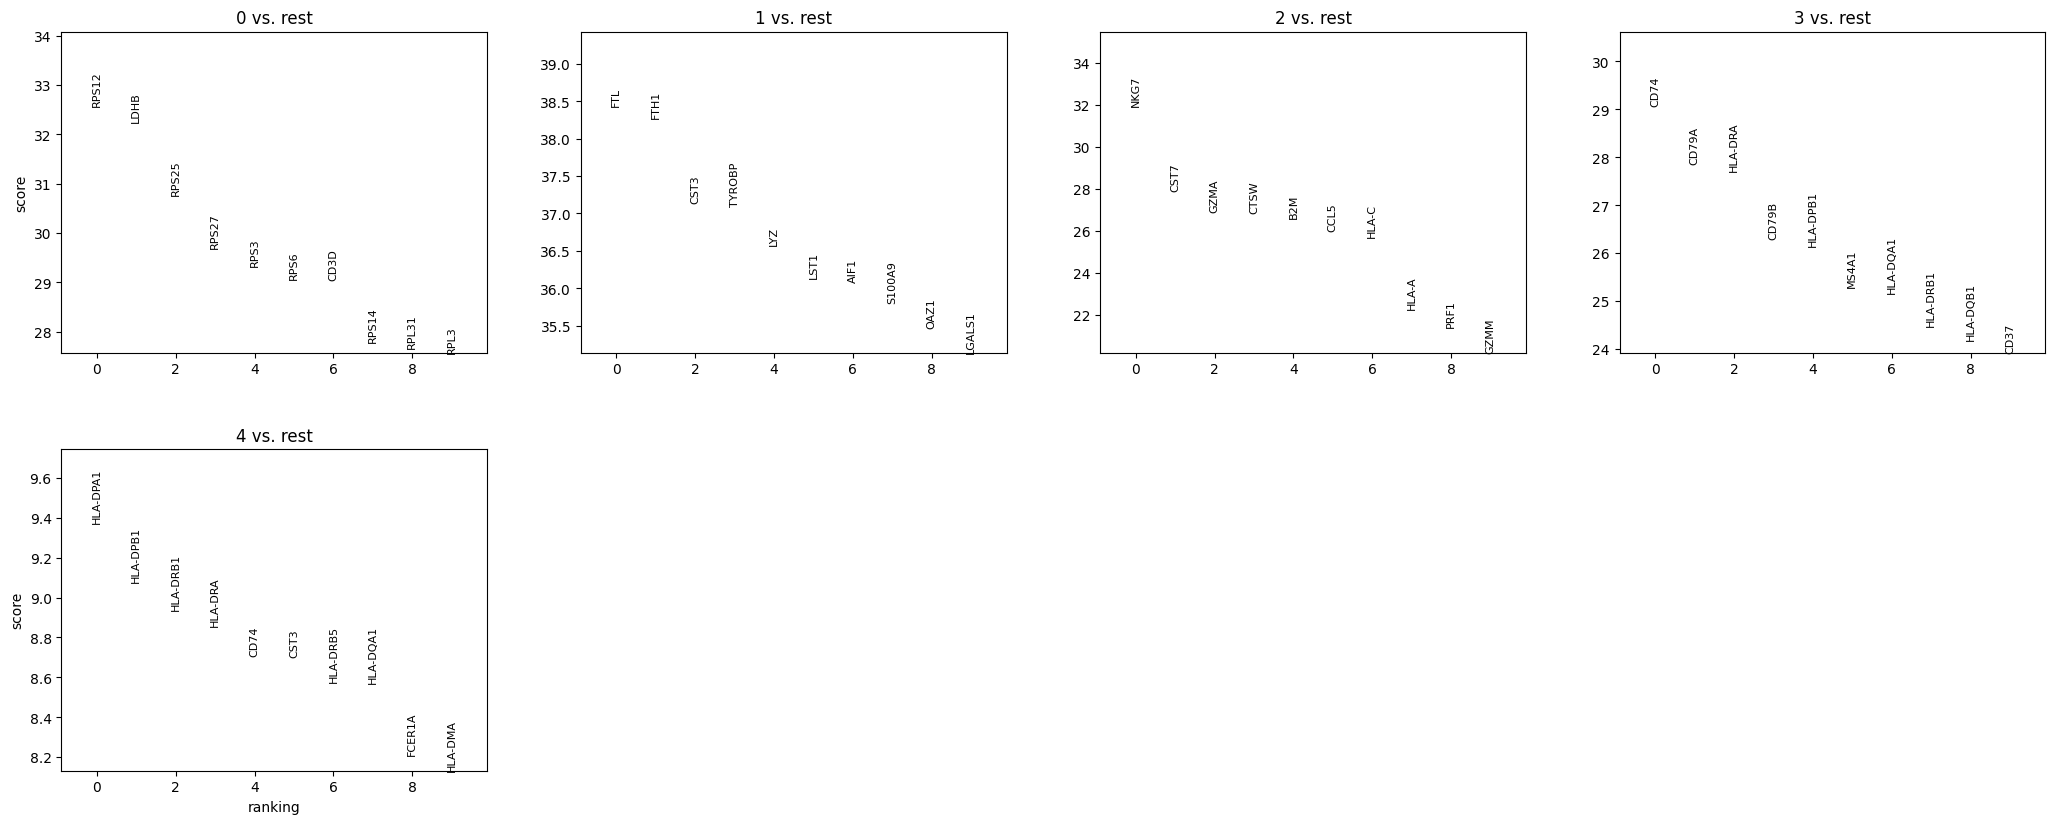

In [ ]:
# Display the top 10 marker candidates per cluster
sc.pl.rank_genes_groups(
    adata,
    n_genes=10,
    sharey=False
)

In [ ]:
# Verify Cell Alignment
print(adata.obs_names.equals(adata_hvg.obs_names))

True


If this returns `True`, their cell names match in both identity and order. If it returns `False`, reindexing **still aligns matching names**, but **you should check for missing labels before proceeding**.

### Visualizing Marker Genes

- `sc.pl.rank_genes_groups()` visualizes the differential-expression results calculated in the previous step.
- `n_genes=10` displays the top 10 ranked genes for each cluster.
- `sharey=False` allows each subplot to use its own y-axis scale instead of sharing the same scale across all clusters.

The plot helps identify genes that distinguish each cluster. Its exact appearance may vary depending on the plotting settings and Scanpy version.

### How to Interpret the Results

For each cluster, ask:

1. Which genes appear near the top of the ranking?
2. Are these genes associated with a known immune cell type?
3. Do multiple genes support the same cell type?
4. Do the expression patterns support the proposed cell-type annotation?

**Example:** If a cluster expresses several T-cell-associated genes, such as `CD3D`, `CD3E` and `IL7R`, this provides stronger evidence for a T-cell identity than relying on a single gene.

**Goal:** Move from numerical cluster IDs to meaningful biological interpretations by identifying the genes that characterize each cluster.

### Important Limitation

This Wilcoxon analysis is useful for exploratory marker discovery. However, cells from the same donor or sample are not independent biological replicates. For formal differential-expression studies, use methods that account for sample or donor structure.

In [ ]:
#Create a marker-gene table
marker_genes = sc.get.rank_genes_groups_df(
    adata,
    group=None
)

marker_genes.head(10)

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,RPS12,32.580498,1.057568,7.748081e-233,1.062572e-228
1,0,LDHB,32.242489,2.709767,4.482925e-228,3.073942e-224
2,0,RPS25,30.771076,1.180997,6.389865e-208,1.752612e-204
3,0,RPS27,29.701086,1.018430,7.434710e-194,1.274495e-190
4,0,RPS3,29.318359,0.884050,6.051636e-189,9.221349e-186
5,0,RPS6,29.073563,0.858424,7.752555e-186,1.063185e-182
6,0,CD3D,29.037683,3.313611,2.201541e-185,2.744722e-182
7,0,RPS14,27.793636,0.756504,5.178377e-170,5.072590e-167
8,0,RPL31,27.662956,1.129231,1.949426e-168,1.782295e-165
9,0,RPL3,27.569496,0.855939,2.583953e-167,2.214771e-164


### Extracting Marker-Gene Results

- `sc.get.rank_genes_groups_df()` extracts the differential-expression results from AnnData and converts them into a Pandas DataFrame.
- `adata` contains the expression data and the marker-gene analysis results.
- `group=None` retrieves the results for all clusters.
- `.head(10)` displays the first 10 rows of the resulting table.

**Important:** `.head(10)` displays only the first 10 rows of the combined results, not the top 10 genes from each cluster. To examine the top genes separately, we need to filter the table by cluster.

### Creating a Marker-Gene Table

After performing differential-expression analysis, Scanpy ranks genes for each cluster based on their expression differences compared with the remaining cells.

A marker-gene table organizes these results into a structured format, showing which genes are most strongly associated with each cluster.

The table can include:

- **Cluster:** The Leiden cluster to which the gene is associated.
- **Gene:** The name of the ranked gene.
- **Score:** The statistical score calculated by the Wilcoxon test.
- **Log fold change:** The estimated difference in gene expression between the cluster and the remaining cells.
- **Adjusted p-value:** The p-value corrected for multiple statistical tests.

**Purpose:** The table helps identify genes that characterize each cluster and provides evidence for assigning biological identities, such as T cells, B cells or NK cells.

By examining several marker genes together, we can make more reliable cell-type annotations.

In [ ]:
genes = ["CD3D", "MS4A1", "NKG7", "LYZ"]

for gene in genes:
    print(gene, gene in adata.var_names)

CD3D True
MS4A1 True
NKG7 True
LYZ True


### Checking Marker-Gene Availability in adata

This code checks whether the selected marker genes are present in the original AnnData object.

- `genes = ["CD3D", "MS4A1", "NKG7", "LYZ"]` defines a list of four selected marker genes.
- `for gene in genes:` iterates through each gene in the list.
- `gene in adata.var_names` checks whether the gene exists in the gene names stored in `adata.var_names`.
- `print(gene, gene in adata.var_names)` displays the gene name and the result of the check.

**Purpose:** Confirm that the selected marker genes are available in the original dataset before visualizing their expression.

**Interpretation:** `True` means the gene is present, while `False` means it cannot be found in the dataset.

In [ ]:
# Check whether the selected marker genes exist in adata_hvg
genes = ["CD3D", "MS4A1", "NKG7", "LYZ"]

for gene in genes:
    print(gene, gene in adata_hvg.var_names)

CD3D False
MS4A1 True
NKG7 True
LYZ True


### Checking Marker-Gene Availability in adata_hvg

This code checks whether the selected marker genes are included in the subset of 2,000 highly variable genes.

- `genes = ["CD3D", "MS4A1", "NKG7", "LYZ"]` defines the marker genes to check.
- `for gene in genes:` iterates through each selected gene.
- `gene in adata_hvg.var_names` checks whether the gene exists in the highly variable gene subset.
- `print(gene, gene in adata_hvg.var_names)` displays the gene name and whether it is present.

**Purpose:** Determine whether the selected marker genes were retained during highly variable gene selection.

**Interpretation:** `True` means the gene was selected as highly variable, while `False` means it was excluded from the 2,000-gene subset.

**Important:** A gene excluded during highly variable gene selection is not necessarily biologically unimportant. It simply was not selected based on the variability criteria used in this analysis.

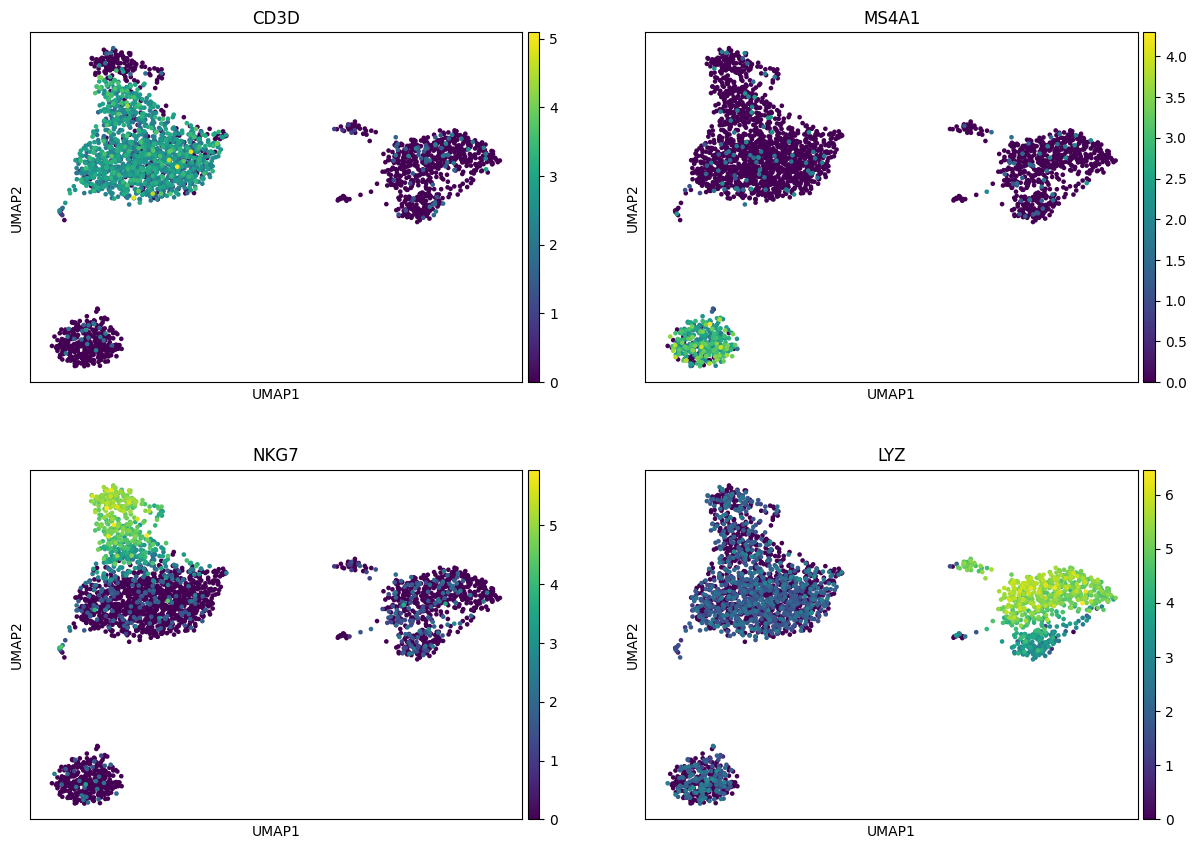

In [ ]:
# Define marker genes for UMAP visualization
marker_genes_to_plot = ["CD3D", "MS4A1", "NKG7", "LYZ"]

# Transfer UMAP coordinates if they are not already in adata
if "X_umap" not in adata.obsm:
    adata.obsm["X_umap"] = adata_hvg.obsm["X_umap"].copy()

# Plot marker gene expression
sc.pl.umap(
    adata,
    color=marker_genes_to_plot,
    cmap="viridis",
    ncols=2
)

### Visualizing Selected Marker Genes

This step visualizes the expression of selected marker genes across the UMAP embedding to help identify potential cell populations.

- `marker_genes_to_plot = ["CD3D", "MS4A1", "NKG7", "LYZ"]` defines four marker genes commonly associated with different immune cell populations.
- `if "X_umap" not in adata.obsm:` checks whether UMAP coordinates are available in the original AnnData object.
- `adata_hvg.obsm["X_umap"]` retrieves the UMAP coordinates calculated using the highly variable genes.
- `.copy()` creates a copy of these coordinates.
- `adata.obsm["X_umap"] = ...` stores the coordinates in `adata`, allowing us to visualize genes from the full set of retained genes using the same UMAP embedding.
- `sc.pl.umap()` generates UMAP plots showing gene expression.
- `color=marker_genes_to_plot` creates a separate plot for each selected gene.
- `cmap="viridis"` sets the color map used to represent gene expression.
- `ncols=2` arranges the plots into two columns.

**Purpose:** Examine the expression patterns of selected marker genes across cell populations and compare them with the Leiden clusters.

**Reference markers:**
- `CD3D`: commonly associated with T cells.
- `MS4A1`: commonly associated with B cells.
- `NKG7`: commonly associated with NK cells and cytotoxic lymphocytes.
- `LYZ`: commonly associated with monocytes and other myeloid cells.

**Interpretation:** Brighter regions indicate higher gene expression, while darker regions indicate lower expression. The distribution of multiple marker genes can help identify potential cell populations within the clusters.

**Important:** A single marker gene is not sufficient to assign a definitive cell type. Cell-type annotation should consider multiple marker genes and their biological associations.

In [ ]:
# Define reference marker genes
marker_panel = {
    "T cells": ["CD3D", "CD3E", "IL7R", "CD8A"],
    "B cells": ["MS4A1", "CD79A"],
    "NK cells": ["NKG7", "GNLY"],
    "Monocytes": ["LYZ", "LST1", "S100A8"],
    "Platelets": ["PPBP", "PF4"]
}



### Comparing Marker Genes Across Leiden Clusters

This step uses a DotPlot to compare the expression of known immune-cell marker genes across Leiden clusters.

- `marker_panel` defines groups of reference marker genes associated with different immune-cell populations.
- `available_markers` checks which selected genes are present in `adata.var_names` and retains only the available genes.
- `missing_genes` identifies marker genes that are not present in the dataset.
- `print("Unavailable genes:", missing_genes)` displays the genes that could not be found.
- `sc.pl.dotplot()` generates a DotPlot to compare marker-gene expression across clusters.
- `var_names=available_markers` specifies the marker genes to visualize, grouped by their associated cell populations.
- `groupby="leiden"` groups cells according to their Leiden cluster assignments.
- `standard_scale="var"` scales the expression of each gene between 0 and 1 to facilitate comparisons across clusters.
- `dendrogram=False` disables hierarchical clustering of the groups.

**How to Interpret the DotPlot:**

- **Dot size:** Represents the percentage of cells in a cluster expressing the gene. Larger dots indicate that a greater proportion of cells express the gene.
- **Dot color:** Represents the average expression level of the gene within the cluster. Darker or more intense colors indicate higher scaled expression.

**Reference Marker Groups:**
- T cells: `CD3D`, `CD3E`, `IL7R`, `CD8A`
- B cells: `MS4A1`, `CD79A`
- NK cells: `NKG7`, `GNLY`
- Monocytes: `LYZ`, `LST1`, `S100A8`
- Platelets: `PPBP`, `PF4`

**Purpose:** Identify clusters with expression patterns associated with known immune-cell populations and support cell-type annotation.

**Important:** These genes are reference markers, not definitive cell-type labels. Their expression patterns should be interpreted together with the marker-gene ranking results and other biological evidence.

In [ ]:
# Keep only genes available in adata
available_markers = {
    cell_type: [
        gene for gene in genes
        if gene in adata.var_names
    ]
    for cell_type, genes in marker_panel.items()
}

# Identify unavailable marker genes
missing_genes = [
    gene
    for genes in marker_panel.values()
    for gene in genes
    if gene not in adata.var_names
]

# Display unavailable genes
print("Unavailable genes:", missing_genes)

Unavailable genes: []


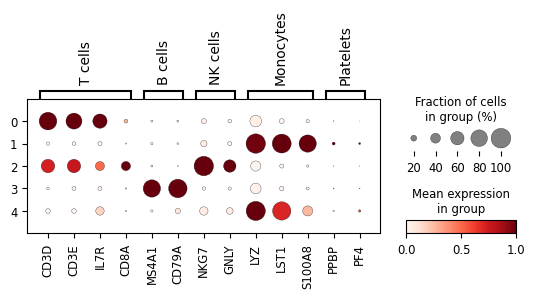

In [ ]:
# Visualize marker expression across clusters
sc.pl.dotplot(
    adata,
    var_names=available_markers,
    groupby="leiden",
    standard_scale="var",
    dendrogram=False
)

In [ ]:
# Display the top 5 marker genes per cluster
for cluster in adata.obs["leiden"].cat.categories:
    print(f"\nCluster {cluster}")
    display(
        marker_genes[marker_genes["group"] == cluster]
        [["names", "logfoldchanges", "pvals_adj"]]
        .head(5)
    )


Cluster 0


,names,logfoldchanges,pvals_adj
0,RPS12,1.057568,1.062572e-228
1,LDHB,2.709767,3.073942e-224
2,RPS25,1.180997,1.752612e-204
3,RPS27,1.018430,1.274495e-190
4,RPS3,0.884050,9.221349e-186



Cluster 1


,names,logfoldchanges,pvals_adj
13714,FTL,3.793267,0.000000e+00
13715,FTH1,3.232908,0.000000e+00
13716,CST3,6.532529,3.197997e-298
13717,TYROBP,6.129173,8.852375e-298
13718,LYZ,5.786509,1.902751e-289



Cluster 2


,names,logfoldchanges,pvals_adj
27428,NKG7,7.162548,3.821465e-220
27429,CST7,6.215672,3.552116e-167
27430,GZMA,5.869606,1.819241e-155
27431,CTSW,4.634359,4.321632e-155
27432,B2M,0.974476,2.562371e-152



Cluster 3


,names,logfoldchanges,pvals_adj
41142,CD74,4.041737,9.617540e-182
41143,CD79A,7.665653,6.710588e-167
41144,HLA-DRA,4.840232,3.063741e-165
41145,CD79B,5.405741,1.068689e-148
41146,HLA-DPB1,4.047682,3.761130e-147



Cluster 4


,names,logfoldchanges,pvals_adj
54856,HLA-DPA1,4.397467,9.799513e-17
54857,HLA-DPB1,4.454283,7.551072e-16
54858,HLA-DRB1,4.331961,1.820721e-15
54859,HLA-DRA,4.647645,2.831759e-15
54860,CD74,3.682486,7.465370e-15


### Examining Top Marker Genes for Cell-Type Annotation

This step displays the five highest-ranked marker genes for each Leiden cluster to help identify potential cell types.

- `for cluster in adata.obs["leiden"].cat.categories` iterates through all Leiden clusters.
- `marker_genes[...]` selects the marker-gene results belonging to the current cluster.
- `group` identifies the cluster associated with each marker gene.
- `names` displays the gene names.
- `logfoldchanges` shows the estimated difference in gene expression.
- `pvals_adj` shows the adjusted p-values, accounting for multiple statistical tests.
- `.head(5)` selects the first five ranked genes for each cluster.

**Purpose:** Identify genes that distinguish each cluster and use their known biological associations to support cell-type annotation.

## Inspect Top Marker Genes per Cluster

After identifying marker genes using the Wilcoxon rank-sum test, we examine the top five marker genes for each Leiden cluster.

These genes help us identify the biological characteristics of each cluster and infer its potential cell type.

## Validate Cluster Identities Using Known Marker Genes

We examine established immune-cell marker genes to validate the preliminary cluster annotations.

This helps distinguish closely related populations, particularly T cells from NK cells and dendritic cells from other antigen-presenting cells.


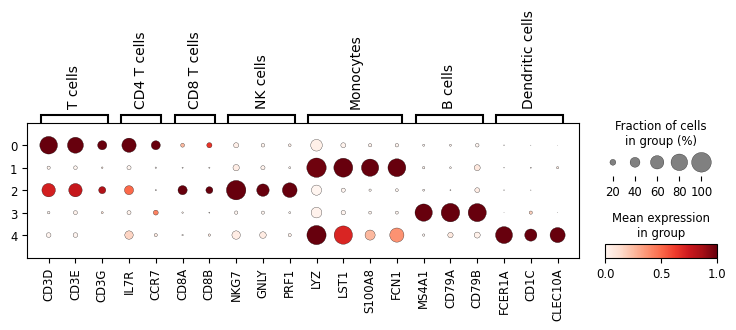

In [ ]:
marker_validation = {
    "T cells": ["CD3D", "CD3E", "CD3G"],
    "CD4 T cells": ["IL7R", "CCR7"],
    "CD8 T cells": ["CD8A", "CD8B"],
    "NK cells": ["NKG7", "GNLY", "PRF1"],
    "Monocytes": ["LYZ", "LST1", "S100A8", "FCN1"],
    "B cells": ["MS4A1", "CD79A", "CD79B"],
    "Dendritic cells": ["FCER1A", "CD1C", "CLEC10A"]
}

available_markers = {
    cell_type: [
        gene for gene in genes
        if gene in adata.var_names
    ]
    for cell_type, genes in marker_validation.items()
}

sc.pl.dotplot(
    adata,
    available_markers,
    groupby="leiden",
    standard_scale="var"
)

## Interpretation of the Marker Gene DotPlot

The DotPlot is used to validate the preliminary cell-type annotations by examining the expression patterns of known immune-cell marker genes across the five Leiden clusters.

- **Dot size** represents the proportion of cells in each cluster expressing a particular gene.
- **Dot color** represents the average expression level of that gene within the cluster. Since `standard_scale="var"` is used, expression is scaled separately for each gene across clusters.

### Marker Gene Interpretation

| Cell population | Marker genes | Interpretation |
|---|---|---|
| T cells | CD3D, CD3E, CD3G | Support T-cell identity |
| CD4 T cells | IL7R, CCR7 | Support CD4 T-cell identity, particularly naive and memory populations |
| CD8 T cells | CD8A, CD8B | Support CD8 T-cell identity |
| NK cells | NKG7, GNLY, PRF1 | Indicate cytotoxic activity and support NK-cell identity |
| Monocytes | LYZ, LST1, S100A8, FCN1 | Support monocyte and myeloid-cell identity |
| B cells | MS4A1, CD79A, CD79B | Support B-cell identity |
| Dendritic cells | FCER1A, CD1C, CLEC10A | Support conventional dendritic-cell identity |

### Points to Consider

- T cells and NK cells can share cytotoxic markers. CD3D and CD3E help distinguish T cells from NK cells.
- Monocytes and dendritic cells can share antigen-presentation-related genes. Multiple markers are needed to distinguish these populations.
- B cells also express MHC class II genes, so HLA-DRA, HLA-DPA1 and CD74 alone are not sufficient to identify dendritic cells.
- A missing or weak marker does not necessarily mean that a cell population is absent. Its expression may be low or the gene may not be included in the selected marker panel.

### Annotation Strategy

Cell-type annotations should be based on the combined expression patterns of multiple established marker genes rather than a single marker.

The DotPlot provides additional evidence for evaluating the preliminary cluster identities obtained from differential marker-gene ranking. Final annotations will be assigned after examining these expression patterns.